# ABCDario — Modelo multitarea único A–Z
## Letra + Movimiento + Relación facial

Esta versión usa **un único modelo multitarea**.

El modelo recibe secuencias de landmarks de:
- manos
- rostro
- pose/hombros
- relaciones mano ↔ rostro

y produce **3 salidas simultáneas**:

1. `letter`: letra A–Z
2. `motion`: estática (0) / dinámica (1)
3. `face`: sin relación facial (0) / con relación facial (1)

### Importante
Las propiedades `motion` y `face` son independientes.

Ejemplos:
- `C = motion 0, face 0`
- `E = motion 0, face 1`
- `J = motion 1, face 0`
- una futura letra dinámica facial puede ser `motion 1, face 1`

Con A–G solamente, `motion` tendrá únicamente ejemplos 0. Cuando agregues J/Z u otras dinámicas, el mismo notebook podrá entrenar la salida `motion` con 0/1 sin cambiar la arquitectura.


In [ ]:
# ============================================================
# 1. INSTALACIÓN - COMPATIBLE CON BACKEND PYTHON 3.10
# ============================================================
# IMPORTANTE:
# El backend con Python 3.10 puede usar Keras 3.12.4, pero NO Keras 3.13.2.
# Entrenamos y guardamos el modelo con:
#   TensorFlow 2.20.0
#   Keras 3.12.4
#
# Si Colab ya tenía importado TensorFlow/Keras antes de ejecutar esta celda,
# reiniciá el entorno después de la instalación y volvé a ejecutar desde aquí.

!pip -q install --upgrade \
    "tensorflow==2.20.0" \
    "keras==3.12.4" \
    mediapipe \
    opencv-python \
    scikit-learn \
    matplotlib \
    seaborn

import os
import json
import random
import math
import sys
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import keras

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)

# Cortamos inmediatamente si Colab no quedó con las versiones correctas.
assert tf.__version__.startswith("2.20."), (
    f"TensorFlow incorrecto: {tf.__version__}. "
    "Debe ser 2.20.x"
)
assert keras.__version__ == "3.12.4", (
    f"Keras incorrecto: {keras.__version__}. "
    "Debe ser 3.12.4. Reiniciá el entorno de ejecución de Colab "
    "y ejecutá nuevamente desde esta celda."
)

print("✅ Entorno compatible con backend Python 3.10")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.9/37.9 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 18.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 3.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-hub 0.26.0 requires keras>=3.13, but you have keras 3.12.4 which is incompatible.
Python: 3.13.15 (main, Aug  6 2026, 11:06:23) [GCC 11.4.0]
TensorFlow: 2.20.0
Keras: 3.12.4
NumPy: 2.1.3
✅ Entorno compatible con backend Python 3.10


In [ ]:
# ============================================================
# 2. GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# CAMBIAR solamente si tu carpeta tiene otro nombre
DATASET_ROOT = Path("/content/drive/MyDrive/ABCDario")

# Carpeta donde se guardarán landmarks y modelos
OUTPUT_ROOT = DATASET_ROOT / "multitask_output27/08"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_ROOT)
print("Existe:", DATASET_ROOT.exists())


Mounted at /content/drive
Dataset: /content/drive/MyDrive/ABCDario
Existe: True


In [ ]:
# ============================================================
# 3. CONFIGURACIÓN DEL ALFABETO
# ============================================================

# Propiedades independientes.
# Agregá nuevas letras aquí cuando estén disponibles.

LETTER_PROPERTIES = {
    "A": {"motion": 0, "face": 0},
    "B": {"motion": 0, "face": 0},
    "C": {"motion": 0, "face": 0},
    "D": {"motion": 0, "face": 0},
    "E": {"motion": 0, "face": 1},
    "F": {"motion": 0, "face": 0},
    "G": {"motion": 0, "face": 0},
    "H": {"motion": 1, "face": 1},
    "I": {"motion": 0, "face": 1},
    "J": {"motion": 1, "face": 1},
    "K": {"motion": 0, "face": 0},
    "L": {"motion": 0, "face": 0},
    "M": {"motion": 0, "face": 0},
    "N": {"motion": 0, "face": 0},
    "Ñ": {"motion": 0, "face": 0},
    "O": {"motion": 0, "face": 0},
    "P": {"motion": 0, "face": 0},
    "Q": {"motion": 0, "face": 0},
    "R": {"motion": 0, "face": 0},
    "S": {"motion": 0, "face": 1},
    "T": {"motion": 0, "face": 1},
    "U": {"motion": 0, "face": 0},
    "V": {"motion": 0, "face": 0},
    "W": {"motion": 0, "face": 0},
    "X": {"motion": 0, "face": 0},
    "Y": {"motion": 0, "face": 1},
    "Z": {"motion": 1, "face": 0},

    # Preparadas para cuando agregues sus videos:
    #"J": {"motion": 1, "face": 0},
    #"Z": {"motion": 1, "face": 0},

    # Ejemplo de futura letra dinámica + rostro:
    # "X": {"motion": 1, "face": 1},
}

# Durante esta etapa solo procesamos las carpetas que realmente existen.
AVAILABLE_CLASSES = sorted([
    letter for letter in LETTER_PROPERTIES
    if (DATASET_ROOT / letter).exists()
])

# Las clases del clasificador de letra son A-Z, pero Keras
# solo puede entrenar las clases que tengan datos.
CLASSES = AVAILABLE_CLASSES
CLASS_TO_ID = {c: i for i, c in enumerate(CLASSES)}
ID_TO_CLASS = {i: c for c, i in CLASS_TO_ID.items()}

print("Clases encontradas:", CLASSES)
print("Propiedades:")
for c in CLASSES:
    print(c, LETTER_PROPERTIES[c])


Clases encontradas: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'Ñ']
Propiedades:
A {'motion': 0, 'face': 0}
B {'motion': 0, 'face': 0}
C {'motion': 0, 'face': 0}
D {'motion': 0, 'face': 0}
E {'motion': 0, 'face': 1}
F {'motion': 0, 'face': 0}
G {'motion': 0, 'face': 0}
H {'motion': 1, 'face': 1}
I {'motion': 0, 'face': 1}
J {'motion': 1, 'face': 1}
K {'motion': 0, 'face': 0}
L {'motion': 0, 'face': 0}
M {'motion': 0, 'face': 0}
N {'motion': 0, 'face': 0}
O {'motion': 0, 'face': 0}
P {'motion': 0, 'face': 0}
Q {'motion': 0, 'face': 0}
R {'motion': 0, 'face': 0}
S {'motion': 0, 'face': 1}
T {'motion': 0, 'face': 1}
U {'motion': 0, 'face': 0}
V {'motion': 0, 'face': 0}
W {'motion': 0, 'face': 0}
X {'motion': 0, 'face': 0}
Y {'motion': 0, 'face': 1}
Z {'motion': 1, 'face': 0}
Ñ {'motion': 0, 'face': 0}


## 4. MediaPipe

Usamos MediaPipe Tasks para evitar depender de `mp.solutions`, que puede no existir en determinadas versiones recientes de MediaPipe.

El extractor intenta obtener:
- hasta 2 manos
- rostro
- pose

Además calcula relaciones entre mano y rostro para ayudar especialmente a diferenciar casos como **C/E**.


In [ ]:
# ============================================================
# 4. MEDIAPIPE TASKS — VIDEO MODE
# ============================================================

!wget -q -O /content/hand_landmarker.task \
  https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

!wget -q -O /content/face_landmarker.task \
  https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task

!wget -q -O /content/pose_landmarker.task \
  https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/latest/pose_landmarker_lite.task

import mediapipe as mp

from mediapipe.tasks import python
from mediapipe.tasks.python import vision

BaseOptions = python.BaseOptions

# ============================================================
# MANOS
# ============================================================

def create_hand_detector():
    options = vision.HandLandmarkerOptions(
        base_options=BaseOptions(
            model_asset_path="/content/hand_landmarker.task"
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.35,
        min_hand_presence_confidence=0.35,
        min_tracking_confidence=0.35,
    )

    return vision.HandLandmarker.create_from_options(
        options
    )

# ============================================================
# ROSTRO
# ============================================================

def create_face_detector():
    options = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(
            model_asset_path="/content/face_landmarker.task"
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_faces=1,
        min_face_detection_confidence=0.35,
        min_face_presence_confidence=0.35,
        min_tracking_confidence=0.35,
    )

    return vision.FaceLandmarker.create_from_options(
        options
    )

# ============================================================
# POSE
# ============================================================

def create_pose_detector():
    options = vision.PoseLandmarkerOptions(
        base_options=BaseOptions(
            model_asset_path="/content/pose_landmarker.task"
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1,
        min_pose_detection_confidence=0.35,
        min_pose_presence_confidence=0.35,
        min_tracking_confidence=0.35,
    )

    return vision.PoseLandmarker.create_from_options(
        options
    )

# ============================================================
# CREAR DETECTORES
# ============================================================

#hand_detector = vision.HandLandmarker.create_from_options(
 #   hand_options
#)

#face_detector = vision.FaceLandmarker.create_from_options(
 #   face_options
#)

#pose_detector = vision.PoseLandmarker.create_from_options(
 #   pose_options
#)

print("✅ Hand Landmarker: VIDEO mode")
print("✅ Face Landmarker: VIDEO mode")
print("✅ Pose Landmarker: VIDEO mode")
print("✅ Detectores listos")


✅ Hand Landmarker: VIDEO mode
✅ Face Landmarker: VIDEO mode
✅ Pose Landmarker: VIDEO mode
✅ Detectores listos


In [ ]:
# ============================================================
# 5. FEATURES
# ============================================================

# Para no depender de una malla facial enorme, usamos puntos faciales
# relevantes para las relaciones con ojos/nariz/boca.
FACE_INDICES = {
    "left_eye": 33,
    "right_eye": 263,
    "nose": 1,
    "mouth_left": 61,
    "mouth_right": 291,
    "chin": 152,
}

# Pose: hombros y codos principalmente
POSE_INDICES = {
    "left_shoulder": 11,
    "right_shoulder": 12,
    "left_elbow": 13,
    "right_elbow": 14,
}

SEQUENCE_LENGTH = 30
FEATURES_PER_FRAME = None  # se define automáticamente después


def safe_point_distance(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)))


def normalize_landmarks(points, reference=None):
    points = np.asarray(points, dtype=np.float32)

    if len(points) == 0:
        return points

    if reference is None:
        reference = points[0]

    centered = points - reference
    scale = np.max(np.linalg.norm(centered, axis=1))

    if scale < 1e-6:
        scale = 1.0

    return centered / scale


def get_hand_vector(hand):
    # 21 landmarks x 3
    arr = np.array([[p.x, p.y, p.z] for p in hand], dtype=np.float32)
    return normalize_landmarks(arr).flatten()


def get_face_points(face_landmarks):
    result = {}
    for name, idx in FACE_INDICES.items():
        p = face_landmarks[idx]
        result[name] = np.array([p.x, p.y, p.z], dtype=np.float32)
    return result


def get_pose_points(pose_landmarks):
    result = {}
    for name, idx in POSE_INDICES.items():
        if idx < len(pose_landmarks):
            p = pose_landmarks[idx]
            result[name] = np.array([p.x, p.y, p.z], dtype=np.float32)
    return result


def relation_features(hand, face_points):
    # Distancias normalizadas mano -> zonas faciales.
    # Estas son especialmente útiles para E y para futuras
    # letras dinámicas que también involucren el rostro.

    tips = [4, 8, 12, 16, 20]
    out = []

    for tip_idx in tips:
        tip = np.array([
            hand[tip_idx].x,
            hand[tip_idx].y,
            hand[tip_idx].z
        ], dtype=np.float32)

        for key in [
            "left_eye",
            "right_eye",
            "nose",
            "mouth_left",
            "mouth_right",
            "chin",
        ]:
            out.append(safe_point_distance(tip, face_points[key]))

    return np.asarray(out, dtype=np.float32)


def e_specific_features(hand, face_points):
    # Información adicional para el caso E:
    # posición de las puntas respecto del centro ocular.
    eye_center = (
        face_points["left_eye"] +
        face_points["right_eye"]
    ) / 2.0

    tips = [8, 12, 16, 20]
    out = []

    for tip_idx in tips:
        tip = np.array([
            hand[tip_idx].x,
            hand[tip_idx].y,
            hand[tip_idx].z
        ], dtype=np.float32)

        d = tip - eye_center
        out.extend([float(d[0]), float(d[1]), float(d[2])])
        out.append(float(np.linalg.norm(d)))

    return np.asarray(out, dtype=np.float32)


def frame_features(result_hand, result_face, result_pose):
    features = []

    # --------------------------------------------------------
    # MANOS
    # --------------------------------------------------------
    hands = result_hand.hand_landmarks

    hand_vectors = []

    for hand in hands[:2]:
        hand_vectors.append(get_hand_vector(hand))

    # Siempre reservamos espacio para 2 manos
    while len(hand_vectors) < 2:
        hand_vectors.append(np.zeros(63, dtype=np.float32))

    features.extend(hand_vectors)

    # --------------------------------------------------------
    # ROSTRO
    # --------------------------------------------------------
    if result_face.face_landmarks:
        face_points = get_face_points(result_face.face_landmarks[0])

        face_vec = []
        for key in FACE_INDICES:
            face_vec.extend(face_points[key])

        features.append(np.asarray(face_vec, dtype=np.float32))
    else:
        face_points = None
        features.append(np.zeros(len(FACE_INDICES) * 3, dtype=np.float32))

    # --------------------------------------------------------
    # POSE
    # --------------------------------------------------------
    if result_pose.pose_landmarks:
        pose_points = get_pose_points(result_pose.pose_landmarks[0])

        pose_vec = []
        for key in POSE_INDICES:
            pose_vec.extend(pose_points[key])

        features.append(np.asarray(pose_vec, dtype=np.float32))
    else:
        features.append(np.zeros(len(POSE_INDICES) * 3, dtype=np.float32))

    # --------------------------------------------------------
    # RELACIONES MANO-ROSTRO
    # --------------------------------------------------------
    relation_size = 5 * len(FACE_INDICES)

    for hand_idx in range(2):
        if hand_idx < len(hands) and face_points is not None:
            rel = relation_features(hands[hand_idx], face_points)
            features.append(rel)
        else:
            features.append(np.zeros(relation_size, dtype=np.float32))

    # Features específicas de E para ambas manos
    e_size = 4 * 4

    for hand_idx in range(2):
        if hand_idx < len(hands) and face_points is not None:
            features.append(e_specific_features(hands[hand_idx], face_points))
        else:
            features.append(np.zeros(e_size, dtype=np.float32))

    return np.concatenate(features).astype(np.float32)


def detect_frame(
    frame_bgr,
    timestamp_ms,
    hand_detector,
    face_detector,
    pose_detector
):
    rgb = cv2.cvtColor(
        frame_bgr,
        cv2.COLOR_BGR2RGB
    )

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    h = hand_detector.detect_for_video(
        mp_image,
        timestamp_ms
    )

    f = face_detector.detect_for_video(
        mp_image,
        timestamp_ms
    )

    p = pose_detector.detect_for_video(
        mp_image,
        timestamp_ms
    )

    return frame_features(
        h,
        f,
        p
    )


In [ ]:
# ============================================================
# 6. EXTRAER UNA SECUENCIA DE 30 FRAMES
# ============================================================

def extract_sequence_from_video(
    video_path,
    sequence_length=30
):

    cap = cv2.VideoCapture(
        str(video_path)
    )

    if not cap.isOpened():
        print(
            "❌ No se pudo abrir:",
            video_path
        )
        return None

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    if not fps or fps <= 0:
        fps = 30.0

    total_frames = int(
        cap.get(
            cv2.CAP_PROP_FRAME_COUNT
        )
    )

    if total_frames <= 0:
        cap.release()
        return None

    # ========================================================
    # DETECTORES NUEVOS PARA ESTE VIDEO
    # ========================================================

    hand_detector = create_hand_detector()
    face_detector = create_face_detector()
    pose_detector = create_pose_detector()

    # ========================================================
    # 30 FRAMES DISTRIBUIDOS EN TODO EL VIDEO
    # ========================================================

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        sequence_length
    ).astype(int)

    sequence = []

    previous_timestamp = -1

    try:

        for frame_number, idx in enumerate(
            frame_indices
        ):

            cap.set(
                cv2.CAP_PROP_POS_FRAMES,
                int(idx)
            )

            ok, frame = cap.read()

            if not ok:
                print(
                    f"⚠️ No se pudo leer "
                    f"frame {idx}"
                )
                continue

            # ================================================
            # TIMESTAMP
            # ================================================

            timestamp_ms = int(
                idx * 1000 / fps
            )

            # Garantizar incremento estricto
            if timestamp_ms <= previous_timestamp:
                timestamp_ms = (
                    previous_timestamp + 1
                )

            previous_timestamp = timestamp_ms

            try:

                features = detect_frame(
                    frame,
                    timestamp_ms,
                    hand_detector,
                    face_detector,
                    pose_detector
                )

                if features is not None:

                    sequence.append(
                        features
                    )

            except Exception as e:

                print(
                    f"⚠️ Frame {idx}:",
                    repr(e)
                )

    finally:

        cap.release()

        # ====================================================
        # CERRAR LOS DETECTORES DEL VIDEO
        # ====================================================

        hand_detector.close()
        face_detector.close()
        pose_detector.close()

    # ========================================================
    # VALIDAR
    # ========================================================

    if len(sequence) == 0:

        print(
            "❌ No se pudo extraer ningún frame:",
            video_path
        )

        return None

    # Si faltaron algunos frames, repetir el último válido
    while len(sequence) < sequence_length:

        sequence.append(
            sequence[-1].copy()
        )

    sequence = np.stack(
        sequence[:sequence_length]
    ).astype(
        np.float32
    )

    return sequence


# Detectar dimensión automáticamente
test_videos = list((DATASET_ROOT / CLASSES[0]).glob("*.mp4"))

if not test_videos:
    raise RuntimeError(f"No hay videos .mp4 en {DATASET_ROOT / CLASSES[0]}")

tmp_seq = extract_sequence_from_video(test_videos[0], SEQUENCE_LENGTH)
FEATURES_PER_FRAME = tmp_seq.shape[-1]

print("FEATURES_PER_FRAME =", FEATURES_PER_FRAME)
print("SEQUENCE_LENGTH =", SEQUENCE_LENGTH)


FEATURES_PER_FRAME = 248
SEQUENCE_LENGTH = 30


In [ ]:
# ============================================================
# 7. DESCUBRIR VIDEOS Y HACER SPLIT TRAIN / VAL / TEST
# ============================================================

random.seed(42)
np.random.seed(42)

all_samples = []

for letter in CLASSES:
    folder = DATASET_ROOT / letter
    videos = sorted([
        p for p in folder.iterdir()
        if p.suffix.lower() in [".mp4", ".avi", ".mov", ".mkv"]
    ])

    print(f"{letter}: {len(videos)} videos")

    for video in videos:
        all_samples.append({
            "path": str(video),
            "letter": letter,
            "motion": LETTER_PROPERTIES[letter]["motion"],
            "face": LETTER_PROPERTIES[letter]["face"],
        })

# Split estratificado por letra.
train_items, temp_items = train_test_split(
    all_samples,
    test_size=0.30,
    random_state=42,
    stratify=[x["letter"] for x in all_samples]
)

val_items, test_items = train_test_split(
    temp_items,
    test_size=0.50,
    random_state=42,
    stratify=[x["letter"] for x in temp_items]
)

print()
print("TRAIN:", len(train_items))
print("VAL:", len(val_items))
print("TEST:", len(test_items))


A: 36 videos
B: 35 videos
C: 44 videos
D: 44 videos
E: 37 videos
F: 37 videos
G: 44 videos
H: 34 videos
I: 33 videos
J: 35 videos
K: 39 videos
L: 41 videos
M: 41 videos
N: 34 videos
O: 41 videos
P: 37 videos
Q: 33 videos
R: 37 videos
S: 39 videos
T: 40 videos
U: 40 videos
V: 34 videos
W: 30 videos
X: 32 videos
Y: 39 videos
Z: 30 videos
Ñ: 29 videos

TRAIN: 696
VAL: 149
TEST: 150


In [ ]:
import shutil

if CACHE_ROOT.exists():
    shutil.rmtree(CACHE_ROOT)

CACHE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("✅ CACHE COMPLETAMENTE ELIMINADO")

NameError: name 'CACHE_ROOT' is not defined

In [ ]:
test_videos = [
    "/content/drive/MyDrive/ABCDario/A/a_01.mp4",
    "/content/drive/MyDrive/ABCDario/A/a_02.mp4",
    "/content/drive/MyDrive/ABCDario/B/b_01.mp4",
    "/content/drive/MyDrive/ABCDario/C/c_01.mp4",
    "/content/drive/MyDrive/ABCDario/E/e_01.mp4",
]

for video in test_videos:

    print("\nVIDEO:", video)

    try:

        seq = extract_sequence_from_video(
            video,
            30
        )

        if seq is None:
            print("❌ None")

        else:
            print(
                "✅",
                seq.shape
            )

    except Exception as e:

        print(
            "❌ ERROR:",
            repr(e)
        )

In [ ]:
import cv2

video = "/content/drive/MyDrive/ABCDario/A/a_01.mp4"

cap = cv2.VideoCapture(video)

print("Abierto:", cap.isOpened())
print("FPS:", cap.get(cv2.CAP_PROP_FPS))
print("Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
print("Ancho:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
print("Alto:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))

ok, frame = cap.read()

print("Primer frame:", ok)

if ok:
    print("Shape:", frame.shape)

cap.release()

In [ ]:
#Probemos MediaPipe directamente sobre un solo frame, sin secuencia y sin extract_sequence_from_video():
import cv2
import mediapipe as mp

video = "/content/drive/MyDrive/ABCDario/A/a_01.mp4"

cap = cv2.VideoCapture(video)

ok, frame = cap.read()

cap.release()

if not ok:
    print("❌ No se pudo leer el video")
else:

    print("✅ Frame leído:", frame.shape)

    rgb = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    mp_image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    timestamp_ms = 0

    print("\nProbando MANOS...")

    try:
        result = hand_detector.detect_for_video(
            mp_image,
            timestamp_ms
        )

        print(
            "✅ Manos:",
            len(result.hand_landmarks)
        )

    except Exception as e:
        print(
            "❌ Manos:",
            repr(e)
        )

    print("\nProbando ROSTRO...")

    try:
        result = face_detector.detect_for_video(
            mp_image,
            timestamp_ms
        )

        print(
            "✅ Rostro:",
            len(result.face_landmarks)
        )

    except Exception as e:
        print(
            "❌ Rostro:",
            repr(e)
        )

    print("\nProbando POSE...")

    try:
        result = pose_detector.detect_for_video(
            mp_image,
            timestamp_ms
        )

        print(
            "✅ Pose:",
            len(result.pose_landmarks)
        )

    except Exception as e:
        print(
            "❌ Pose:",
            repr(e)
        )

In [ ]:
# ============================================================
# 8. PROCESAMIENTO DEL DATASET
# ============================================================

CACHE_ROOT = OUTPUT_ROOT / "sequences"
CACHE_ROOT.mkdir(exist_ok=True)

def cache_name(item):
    letter = item["letter"]
    name = Path(item["path"]).stem
    return CACHE_ROOT / f"{letter}_{name}.npy"


def process_items(items, split_name):
    X, y_letter, y_motion, y_face = [], [], [], []

    print("\n" + "=" * 60)
    print("PROCESANDO", split_name.upper())
    print("=" * 60)

    for n, item in enumerate(items, 1):
        cache = cache_name(item)

        try:
            if cache.exists():
                sequence = np.load(cache)
            else:
                sequence = extract_sequence_from_video(
                    item["path"],
                    SEQUENCE_LENGTH
                )
                if sequence is None:
                    print("Sin secuencia:", item["path"])
                    continue
                np.save(cache, sequence)

            X.append(sequence)
            y_letter.append(CLASS_TO_ID[item["letter"]])
            y_motion.append(item["motion"])
            y_face.append(item["face"])

            print(
                f"[{n}/{len(items)}] {item['letter']} "
                f"{Path(item['path']).name}"
            )

        except Exception as e:
            print("ERROR:", item["path"], e)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y_letter, dtype=np.int32),
        np.asarray(y_motion, dtype=np.float32),
        np.asarray(y_face, dtype=np.float32),
    )


X_train, y_letter_train, y_motion_train, y_face_train = process_items(train_items, "train")
X_val, y_letter_val, y_motion_val, y_face_val = process_items(val_items, "validation")
X_test, y_letter_test, y_motion_test, y_face_test = process_items(test_items, "test")

print("Shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)



PROCESANDO TRAIN
[1/696] Q q_23.mp4
[2/696] X x_32.mp4
[3/696] V v_10.mp4
[4/696] C c_39.mp4
[5/696] B b_17.mp4
[6/696] S s_23.mp4
[7/696] N n_06.mp4
[8/696] Z z_09.mp4
[9/696] A a_32.mp4
[10/696] T t_19.mp4
[11/696] Ñ ñ_10.mp4
[12/696] S s_04.mp4
[13/696] C c_27.mp4
[14/696] D d_38.mp4
[15/696] H h_28.mp4
[16/696] T t_43.mp4
[17/696] W w_01.mp4
[18/696] P p_02.mp4
[19/696] V v_12.mp4
[20/696] R r_44.mp4
[21/696] V v_16.mp4
[22/696] D d_39.mp4
[23/696] S s_05.mp4
[24/696] L l_04.mp4
[25/696] S s_32.mp4
[26/696] T t_07.mp4
[27/696] G g_27.mp4
[28/696] J j_28.mp4
[29/696] H h_24.mp4
[30/696] A a_28.mp4
[31/696] J j_02.mp4
[32/696] O o_07.mp4
[33/696] F f_34.mp4
[34/696] K k_26.mp4
[35/696] N n_14.mp4
[36/696] M m_24.mp4
[37/696] U u_20.mp4
[38/696] O o_34.mp4
[39/696] J j_19.mp4
[40/696] C c_17.mp4
[41/696] Ñ ñ_42.mp4
[42/696] L l_24.mp4
[43/696] B b_10.mp4
[44/696] A a_31.mp4
[45/696] Y y_27.mp4
[46/696] N n_31.mp4
[47/696] X x_16.mp4
[48/696] L l_27.mp4
[49/696] Q q_03.mp4
[50/696] 

In [ ]:
# ============================================================
# 8. PROCESAMIENTO DEL DATASET — DIAGNÓSTICO
# ============================================================

CACHE_ROOT = OUTPUT_ROOT / "sequences"
CACHE_ROOT.mkdir(
    parents=True,
    exist_ok=True
)


def cache_name(item):
    letter = item["letter"]
    name = Path(item["path"]).stem

    return CACHE_ROOT / f"{letter}_{name}.npy"


def process_items(items, split_name):

    X = []
    y_letter = []
    y_motion = []
    y_face = []

    errores = []

    print("\n" + "=" * 60)
    print("PROCESANDO", split_name.upper())
    print("=" * 60)

    print("Videos recibidos:", len(items))

    for n, item in enumerate(items, 1):

        cache = cache_name(item)

        try:

            # ==================================================
            # CACHE
            # ==================================================

            if cache.exists():

                sequence = np.load(
                    cache,
                    allow_pickle=False
                )

                print(
                    f"[{n}/{len(items)}] CACHE "
                    f"{item['letter']} "
                    f"{Path(item['path']).name} "
                    f"{sequence.shape}"
                )

            else:

                sequence = extract_sequence_from_video(
                    item["path"],
                    SEQUENCE_LENGTH
                )

                if sequence is None:

                    raise ValueError(
                        "extract_sequence_from_video "
                        "devolvió None"
                    )

                sequence = np.asarray(
                    sequence,
                    dtype=np.float32
                )

                np.save(
                    cache,
                    sequence
                )

                print(
                    f"[{n}/{len(items)}] OK "
                    f"{item['letter']} "
                    f"{Path(item['path']).name} "
                    f"{sequence.shape}"
                )

            # ==================================================
            # VALIDAR SHAPE
            # ==================================================

            if sequence.ndim != 2:

                raise ValueError(
                    f"Shape incorrecto: "
                    f"{sequence.shape}"
                )

            if sequence.shape[0] != SEQUENCE_LENGTH:

                raise ValueError(
                    f"Frames incorrectos: "
                    f"{sequence.shape[0]} "
                    f"!= {SEQUENCE_LENGTH}"
                )

            if sequence.shape[1] != FEATURES_PER_FRAME:

                raise ValueError(
                    f"Features incorrectas: "
                    f"{sequence.shape[1]} "
                    f"!= {FEATURES_PER_FRAME}"
                )

            # ==================================================
            # AGREGAR
            # ==================================================

            X.append(sequence)

            y_letter.append(
                CLASS_TO_ID[item["letter"]]
            )

            y_motion.append(
                item["motion"]
            )

            y_face.append(
                item["face"]
            )

        except Exception as e:

            errores.append(
                {
                    "letter": item["letter"],
                    "path": item["path"],
                    "error": str(e)
                }
            )

            print(
                f"❌ ERROR [{n}/{len(items)}]"
            )

            print(
                "   Letra:",
                item["letter"]
            )

            print(
                "   Video:",
                item["path"]
            )

            print(
                "   Error:",
                repr(e)
            )

    # ========================================================
    # RESULTADO
    # ========================================================

    print("\n" + "-" * 60)
    print("RESULTADO", split_name.upper())
    print("-" * 60)

    print(
        "Videos recibidos:",
        len(items)
    )

    print(
        "Videos correctos:",
        len(X)
    )

    print(
        "Videos con error:",
        len(errores)
    )

    if len(X) > 0:

        X = np.stack(X).astype(
            np.float32
        )

        y_letter = np.asarray(
            y_letter,
            dtype=np.int32
        )

        y_motion = np.asarray(
            y_motion,
            dtype=np.float32
        )

        y_face = np.asarray(
            y_face,
            dtype=np.float32
        )

        print(
            "X:",
            X.shape
        )

    else:

        X = np.empty(
            (0, SEQUENCE_LENGTH, FEATURES_PER_FRAME),
            dtype=np.float32
        )

        y_letter = np.empty(
            (0,),
            dtype=np.int32
        )

        y_motion = np.empty(
            (0,),
            dtype=np.float32
        )

        y_face = np.empty(
            (0,),
            dtype=np.float32
        )

    return (
        X,
        y_letter,
        y_motion,
        y_face,
        errores
    )

In [ ]:
# ============================================================
# 9. COMPROBAR BALANCE DE LETTER / MOTION / FACE
# ============================================================

def show_distribution(name, letters, motions, faces):
    print("\n", name)
    print("Letras:", {
        CLASSES[i]: int(np.sum(letters == i))
        for i in range(len(CLASSES))
    })
    print("Motion:", {
        0: int(np.sum(motions == 0)),
        1: int(np.sum(motions == 1)),
    })
    print("Face:", {
        0: int(np.sum(faces == 0)),
        1: int(np.sum(faces == 1)),
    })

show_distribution("TRAIN", y_letter_train, y_motion_train, y_face_train)
show_distribution("VALIDATION", y_letter_val, y_motion_val, y_face_val)
show_distribution("TEST", y_letter_test, y_motion_test, y_face_test)



 TRAIN
Letras: {'A': 25, 'B': 24, 'C': 31, 'D': 31, 'E': 26, 'F': 26, 'G': 31, 'H': 24, 'I': 23, 'J': 24, 'K': 27, 'L': 29, 'M': 29, 'N': 24, 'O': 29, 'P': 26, 'Q': 23, 'R': 26, 'S': 27, 'T': 28, 'U': 28, 'V': 24, 'W': 21, 'X': 22, 'Y': 27, 'Z': 21, 'Ñ': 20}
Motion: {0: 627, 1: 69}
Face: {0: 517, 1: 179}

 VALIDATION
Letras: {'A': 6, 'B': 5, 'C': 6, 'D': 6, 'E': 5, 'F': 6, 'G': 6, 'H': 5, 'I': 5, 'J': 5, 'K': 6, 'L': 6, 'M': 6, 'N': 5, 'O': 6, 'P': 5, 'Q': 5, 'R': 6, 'S': 6, 'T': 6, 'U': 6, 'V': 5, 'W': 5, 'X': 5, 'Y': 6, 'Z': 5, 'Ñ': 5}
Motion: {0: 134, 1: 15}
Face: {0: 111, 1: 38}

 TEST
Letras: {'A': 5, 'B': 6, 'C': 7, 'D': 7, 'E': 6, 'F': 5, 'G': 7, 'H': 5, 'I': 5, 'J': 6, 'K': 6, 'L': 6, 'M': 6, 'N': 5, 'O': 6, 'P': 6, 'Q': 5, 'R': 5, 'S': 6, 'T': 6, 'U': 6, 'V': 5, 'W': 4, 'X': 5, 'Y': 6, 'Z': 4, 'Ñ': 4}
Motion: {0: 135, 1: 15}
Face: {0: 110, 1: 40}


## 10. Modelo multitarea único

No hay `modelo_static` ni `modelo_motion` separados.

Una sola GRU procesa la secuencia y comparte la representación.

Luego salen tres cabezas:

- `letter_output`: clasificación A–Z
- `motion_output`: estática/dinámica
- `face_output`: sin relación facial/con relación facial

Las pérdidas auxiliares ayudan a que la representación interna aprenda las propiedades de la seña.


In [ ]:
# ============================================================
# VERIFICACIÓN DE COMPATIBILIDAD ANTES DE CREAR EL MODELO
# ============================================================
import tensorflow as tf
import keras

print("TensorFlow activo:", tf.__version__)
print("Keras activo:", keras.__version__)

if keras.__version__ != "3.12.4":
    raise RuntimeError(
        "Este notebook debe crear el modelo con Keras 3.12.4. "
        f"Versión actual: {keras.__version__}. "
        "Reiniciá el runtime y ejecutá nuevamente desde la celda 1."
    )

print("✅ Se puede crear el modelo compatible con Python 3.10")


TensorFlow activo: 2.20.0
Keras activo: 3.12.4
✅ Se puede crear el modelo compatible con Python 3.10


In [ ]:
# ============================================================
# 10. MODELO MULTITAREA ÚNICO
# ============================================================

NUM_LETTERS = len(CLASSES)

inputs = tf.keras.Input(
    shape=(SEQUENCE_LENGTH, FEATURES_PER_FRAME),
    name="landmarks"
)

x = tf.keras.layers.LayerNormalization()(inputs)

x = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(
        128,
        return_sequences=True,
        dropout=0.20,
        recurrent_dropout=0.0
    )
)(x)

x = tf.keras.layers.GRU(
    96,
    dropout=0.20
)(x)

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.30)(x)

# Salida principal
letter_output = tf.keras.layers.Dense(
    NUM_LETTERS,
    activation="softmax",
    name="letter_output"
)(x)

# Propiedad 1: movimiento
motion_output = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="motion_output"
)(x)

# Propiedad 2: relación facial
face_output = tf.keras.layers.Dense(
    1,
    activation="sigmoid",
    name="face_output"
)(x)

model = tf.keras.Model(
    inputs=inputs,
    outputs=[
        letter_output,
        motion_output,
        face_output
    ]
)

# La letra es la tarea principal.
# Las otras dos son tareas auxiliares.
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=2.5e-4
    ),
    loss={
        "letter_output": "sparse_categorical_crossentropy",
        "motion_output": "binary_crossentropy",
        "face_output": "binary_crossentropy",
    },
    loss_weights={
        "letter_output": 1.0,
        "motion_output": 0.30,
        "face_output": 0.40,
    },
    metrics={
        "letter_output": ["accuracy"],
        "motion_output": ["accuracy"],
        "face_output": ["accuracy"],
    }
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ landmarks           │ (None, 30, 248)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 248)   │        496 │ landmarks[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 30, 256)   │    290,304 │ layer_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ (None, 96)        │    101,952 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     12,416 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ letter_output       │ (None, 27)        │      3,483 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ motion_output       │ (None, 1)         │        129 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ face_output (Dense) │ (None, 1)         │        129 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 408,909 (1.56 MB)

 Trainable params: 408,909 (1.56 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print("========================================")
print("VERIFICACIÓN DE DATASET")
print("========================================")

print("X_train:")
print("  type:", type(X_train))
print("  shape:", X_train.shape)
print("  dtype:", X_train.dtype)

print("\nX_val:")
print("  type:", type(X_val))
print("  shape:", X_val.shape)
print("  dtype:", X_val.dtype)

print("\nX_test:")
print("  type:", type(X_test))
print("  shape:", X_test.shape)
print("  dtype:", X_test.dtype)

print("\nModelo espera:")
print(model.input_shape)

print("\nFEATURES_PER_FRAME:")
print(FEATURES_PER_FRAME)

print("\nSEQUENCE_LENGTH:")
print(SEQUENCE_LENGTH)

VERIFICACIÓN DE DATASET
X_train:
  type: <class 'numpy.ndarray'>
  shape: (620, 30, 248)
  dtype: float32

X_val:
  type: <class 'numpy.ndarray'>
  shape: (133, 30, 248)
  dtype: float32

X_test:
  type: <class 'numpy.ndarray'>
  shape: (134, 30, 248)
  dtype: float32

Modelo espera:
(None, 30, 248)

FEATURES_PER_FRAME:
248

SEQUENCE_LENGTH:
30


In [ ]:
# ============================================================
# 11. CALLBACKS
# ============================================================

BEST_MODEL_PATH = OUTPUT_ROOT / "ABCDario_multitask_AZ.keras"

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        str(BEST_MODEL_PATH),
        monitor="val_letter_output_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_letter_output_loss",
        mode="min",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_letter_output_accuracy",
        mode="max",
        patience=60,
        restore_best_weights=True,
        verbose=1
    )
]


In [ ]:
# ============================================================
# 12. ENTRENAMIENTO
# ============================================================

history = model.fit(
    X_train,
    {
        "letter_output": y_letter_train,
        "motion_output": y_motion_train,
        "face_output": y_face_train,
    },
    validation_data=(
        X_val,
        {
            "letter_output": y_letter_val,
            "motion_output": y_motion_val,
            "face_output": y_face_val,
        }
    ),
    epochs=80,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - face_output_accuracy: 0.6863 - face_output_loss: 0.6200 - letter_output_accuracy: 0.0540 - letter_output_loss: 3.3383 - loss: 3.7379 - motion_output_accuracy: 0.8005 - motion_output_loss: 0.5052
Epoch 1: val_letter_output_accuracy improved from None to 0.12752, saving model to /content/drive/MyDrive/ABCDario/multitask_output27/08/ABCDario_multitask_AZ.keras
44/44 ━━━━━━━━━━━━━━━━━━━━ 19s 229ms/step - face_output_accuracy: 0.7098 - face_output_loss: 0.6036 - letter_output_accuracy: 0.0575 - letter_output_loss: 3.3050 - loss: 3.6775 - motion_output_accuracy: 0.8635 - motion_output_loss: 0.4316 - val_face_output_accuracy: 0.7450 - val_face_output_loss: 0.5402 - val_letter_output_accuracy: 0.1275 - val_letter_output_loss: 3.0860 - val_loss: 3.4175 - val_motion_output_accuracy: 0.8993 - val_motion_output_loss: 0.3282 - learning_rate: 2.5000e-04
Epoch 2/80
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - face_output_accuracy: 0.7205 - face_outp

In [ ]:
# ============================================================
# 13. EVALUACIÓN
# ============================================================

results = model.evaluate(
    X_test,
    {
        "letter_output": y_letter_test,
        "motion_output": y_motion_test,
        "face_output": y_face_test,
    },
    verbose=1,
)

print("\nResultados:")
for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - face_output_accuracy: 0.9133 - face_output_loss: 0.2365 - letter_output_accuracy: 0.7667 - letter_output_loss: 0.9756 - loss: 1.1245 - motion_output_accuracy: 0.9467 - motion_output_loss: 0.1599

Resultados:
loss: 1.1245
compile_metrics: 0.9756
letter_output_loss: 0.1599
motion_output_loss: 0.2365
face_output_loss: 0.9133


              precision    recall  f1-score   support

           A       0.80      0.80      0.80         5
           B       0.83      0.83      0.83         6
           C       0.60      0.43      0.50         7
           D       0.50      0.71      0.59         7
           E       0.56      0.83      0.67         6
           F       1.00      0.60      0.75         5
           G       1.00      0.57      0.73         7
           H       0.67      0.40      0.50         5
           I       1.00      1.00      1.00         5
           J       0.86      1.00      0.92         6
           K       0.67      1.00      0.80         6
           L       0.86      1.00      0.92         6
           M       0.60      1.00      0.75         6
           N       1.00      0.80      0.89         5
           O       0.60      0.50      0.55         6
           P       1.00      0.67      0.80         6
           Q       0.71      1.00      0.83         5
           R       0.67    

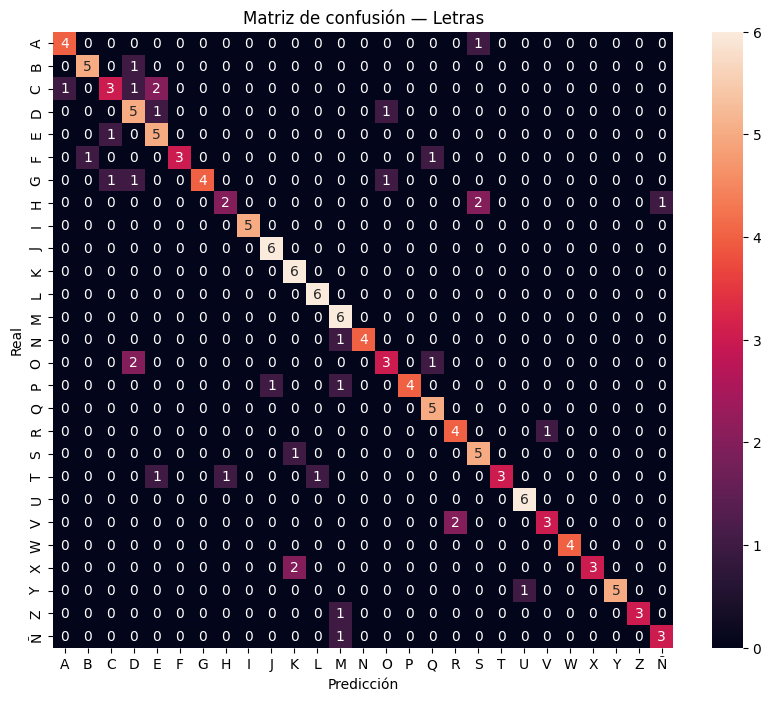

In [ ]:
# ============================================================
# 14. MATRIZ DE CONFUSIÓN DE LETRAS
# ============================================================

pred_letter, pred_motion, pred_face = model.predict(X_test, verbose=0)

pred_letter_ids = np.argmax(pred_letter, axis=1)

print(classification_report(
    y_letter_test,
    pred_letter_ids,
    labels=list(range(NUM_LETTERS)),
    target_names=CLASSES,
    zero_division=0
))

cm = confusion_matrix(
    y_letter_test,
    pred_letter_ids,
    labels=list(range(NUM_LETTERS))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión — Letras")
plt.show()


In [ ]:
# ============================================================
# 15. EVALUAR MOTION Y FACE
# ============================================================

pred_motion_bin = (pred_motion.ravel() >= 0.5).astype(int)
pred_face_bin = (pred_face.ravel() >= 0.5).astype(int)

motion_acc = np.mean(pred_motion_bin == y_motion_test)
face_acc = np.mean(pred_face_bin == y_face_test)

print(f"Motion accuracy: {motion_acc * 100:.2f}%")
print(f"Face accuracy:   {face_acc * 100:.2f}%")

print("\nMotion:")
print(classification_report(
    y_motion_test,
    pred_motion_bin,
    zero_division=0
))

print("Face:")
print(classification_report(
    y_face_test,
    pred_face_bin,
    zero_division=0
))


In [ ]:
# ============================================================
# 16. DIAGNÓSTICO ESPECÍFICO C vs E
# ============================================================

c_id = CLASS_TO_ID.get("C")
e_id = CLASS_TO_ID.get("E")

if c_id is not None and e_id is not None:
    mask = np.isin(y_letter_test, [c_id, e_id])

    print("Muestras C/E en TEST:", int(mask.sum()))

    print(classification_report(
        y_letter_test[mask],
        pred_letter_ids[mask],
        labels=[c_id, e_id],
        target_names=["C", "E"],
        zero_division=0
    ))

    print("\nPredicciones C/E:")
    for real, pred, face_p, motion_p in zip(
        y_letter_test[mask],
        pred_letter_ids[mask],
        pred_face.ravel()[mask],
        pred_motion.ravel()[mask],
    ):
        print(
            f"real={ID_TO_CLASS[int(real)]} "
            f"pred={ID_TO_CLASS[int(pred)]} "
            f"face={face_p:.3f} "
            f"motion={motion_p:.3f}"
        )
else:
    print("C o E todavía no están disponibles en el dataset.")


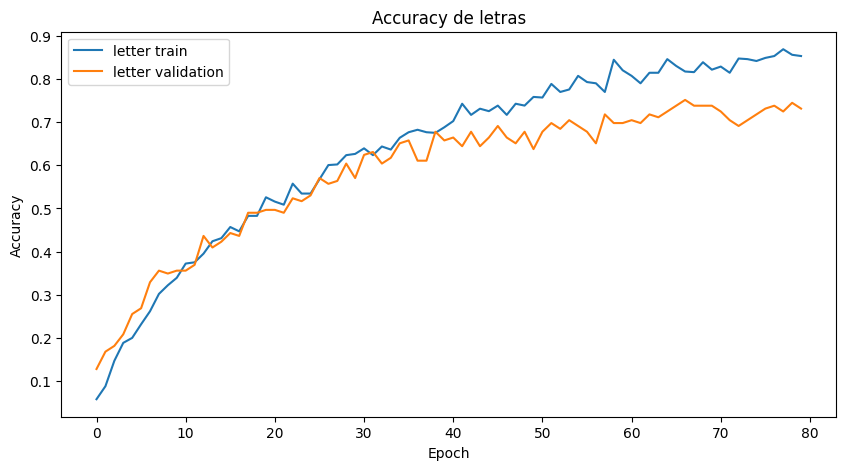

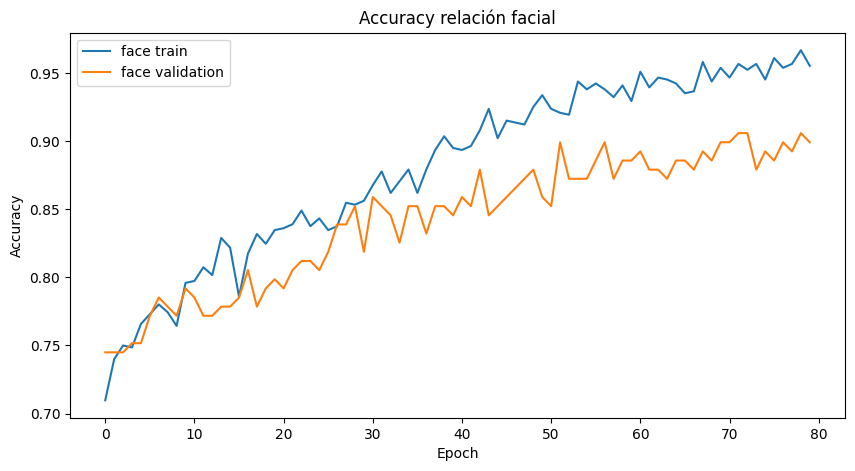

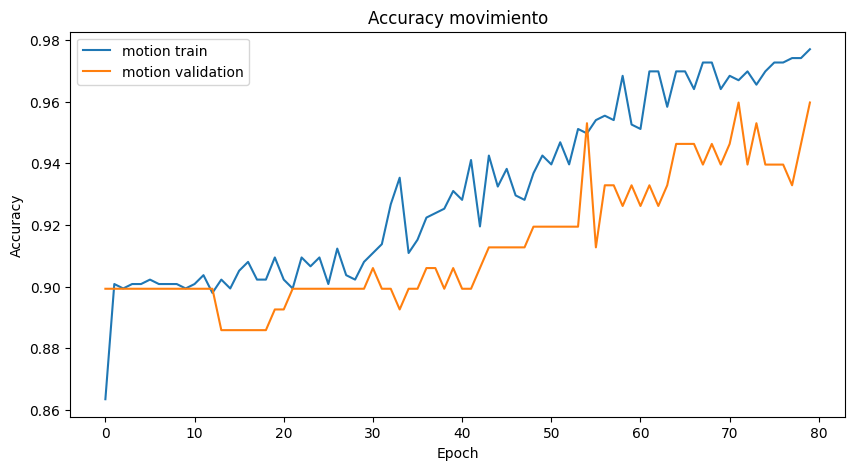

In [ ]:
# ============================================================
# 17. CURVAS DE ENTRENAMIENTO
# ============================================================

plt.figure(figsize=(10, 5))
plt.plot(
    history.history["letter_output_accuracy"],
    label="letter train"
)
plt.plot(
    history.history["val_letter_output_accuracy"],
    label="letter validation"
)
plt.title("Accuracy de letras")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    history.history["face_output_accuracy"],
    label="face train"
)
plt.plot(
    history.history["val_face_output_accuracy"],
    label="face validation"
)
plt.title("Accuracy relación facial")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    history.history["motion_output_accuracy"],
    label="motion train"
)
plt.plot(
    history.history["val_motion_output_accuracy"],
    label="motion validation"
)
plt.title("Accuracy movimiento")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


In [ ]:
# ============================================================
# 18. GUARDAR MODELO + METADATOS
#    Compatible con backend Python 3.10 / Keras 3.12.4
# ============================================================

import keras
import tensorflow as tf

if keras.__version__ != "3.12.4":
    raise RuntimeError(
        "NO se guardará el modelo porque Keras no es 3.12.4. "
        f"Versión actual: {keras.__version__}"
    )

# Guardamos el modelo final con Keras 3.12.4.
model.save(BEST_MODEL_PATH)

metadata = {
    "classes": CLASSES,
    "letter_properties": LETTER_PROPERTIES,
    "sequence_length": SEQUENCE_LENGTH,
    "features_per_frame": int(FEATURES_PER_FRAME),
    "outputs": {
        "letter": "letter_output",
        "motion": "motion_output",
        "face": "face_output",
    },
    "feature_config": {
        "face_indices": FACE_INDICES,
        "pose_indices": POSE_INDICES,
    },
    "training_environment": {
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
        "target_backend_python": "3.10"
    }
}

metadata_path = OUTPUT_ROOT / "metadata.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print("Modelo:", BEST_MODEL_PATH)
print("Metadata:", metadata_path)

# ============================================================
# PRUEBA CRÍTICA:
# cerrar conceptualmente el ciclo de guardado/carga en la misma versión.
# ============================================================
print("\nProbando recarga del .keras recién guardado...")

test_model = keras.models.load_model(
    BEST_MODEL_PATH,
    compile=False
)

print("✅ Modelo recargado correctamente")
print("Input shape:", test_model.input_shape)
print("Outputs:", test_model.output_names)

expected_input = (None, SEQUENCE_LENGTH, FEATURES_PER_FRAME)

if tuple(test_model.input_shape) != tuple(expected_input):
    raise RuntimeError(
        f"Input inesperado: {test_model.input_shape}; "
        f"esperado {expected_input}"
    )

if test_model.output_names != [
    "letter_output",
    "motion_output",
    "face_output"
]:
    raise RuntimeError(
        f"Salidas inesperadas: {test_model.output_names}"
    )

print("\n✅ ARCHIVO LISTO PARA BACKEND PYTHON 3.10 + KERAS 3.12.4")
print("Copiá al backend:")
print("  ", BEST_MODEL_PATH.name)
print("  ", metadata_path.name)


Modelo: /content/drive/MyDrive/ABCDario/multitask_output27/08/ABCDario_multitask_AZ.keras
Metadata: /content/drive/MyDrive/ABCDario/multitask_output27/08/metadata.json

Probando recarga del .keras recién guardado...
✅ Modelo recargado correctamente
Input shape: (None, 30, 248)
Outputs: ListWrapper(['letter_output', 'motion_output', 'face_output'])

✅ ARCHIVO LISTO PARA BACKEND PYTHON 3.10 + KERAS 3.12.4
Copiá al backend:
   ABCDario_multitask_AZ.keras
   metadata.json


In [ ]:
# ============================================================
# 19. FUNCIÓN DE PREDICCIÓN PARA UN VIDEO
# ============================================================

def predict_video(video_path):
    sequence = extract_sequence_from_video(
        video_path,
        SEQUENCE_LENGTH
    )

    if sequence is None:
        raise ValueError("No se pudo extraer la secuencia.")

    sequence = np.expand_dims(sequence, axis=0)

    letter_p, motion_p, face_p = model.predict(
        sequence,
        verbose=0
    )

    letter_id = int(np.argmax(letter_p[0]))

    return {
        "letter": ID_TO_CLASS[letter_id],
        "letter_confidence": float(letter_p[0][letter_id]),
        "motion": int(motion_p[0, 0] >= 0.5),
        "motion_probability": float(motion_p[0, 0]),
        "face": int(face_p[0, 0] >= 0.5),
        "face_probability": float(face_p[0, 0]),
    }

# Ejemplo:
print(predict_video("/content/drive/MyDrive/ABCDario/Z/z_28.mp4"))


{'letter': 'Z', 'letter_confidence': 0.9983569979667664, 'motion': 1, 'motion_probability': 0.8016784191131592, 'face': 0, 'face_probability': 0.0004681964055635035}


## 20. Cuando agregues J/Z

No hace falta crear otro modelo.

Solo asegurate de tener:

```text
ABCDario/
├── A/
├── B/
├── C/
├── D/
├── E/
├── F/
├── G/
├── J/
└── Z/
```

y mantener:

```python
"J": {"motion": 1, "face": 0},
"Z": {"motion": 1, "face": 0},
```

Si una futura letra dinámica involucra el rostro:

```python
"X": {"motion": 1, "face": 1},
```

El mismo modelo multitarea la aprenderá con las tres etiquetas:

```text
letter = X
motion = 1
face = 1
```

No hay que crear un cuarto grupo ni otro modelo.


## Verificación en el backend con Python 3.10

Después de descargar `ABCDario_multitask_AZ.keras` y `metadata.json`,
copiarlos a `backend/model/`.

En el `venvEmociones` usar:

```powershell
python -m pip install --upgrade tensorflow==2.20.0 keras==3.12.4
```

Y comprobar:

```powershell
python -c "import keras; m=keras.models.load_model(r'model\ABCDario_multitask_AZ.keras', compile=False); print('OK', m.input_shape, m.output_names)"
```

Se espera:

```text
OK (None, 30, 248) ['letter_output', 'motion_output', 'face_output']
```
